# Extended Figure 6 — tumour/normal vs tumour-only somatic calling

What the somatic profile looks like when the matched normal is taken away. Two things are shown
side by side: a **benchmark** of tumour-only against tumour/normal on Illumina, where the
tumour/normal calls are the truth set, and the **cross-platform view**, where the same
tumour/normal-vs-tumour-only comparison is repeated for Illumina, Roche and Ultima.

| Panel | Content | Source |
| --- | --- | --- |
| TN-vs-TO concordance | SNV and indel Venn, Illumina, pooled over the cell lines | `purple.somatic.vcf.gz` |
| SNV benchmark | SBS-96 profile and VAF distribution of the TP / FP / FN sets | `purple.somatic.vcf.gz` (`TNC`, `AF`) |
| indel benchmark | COSMIC ID-83 profile and VAF distribution of the TP / FP / FN sets | `purple.somatic.vcf.gz` (`REP_C`, `REP_S`, `RC_MH`, `AF`) |
| variant burden | SNV / MNV / indel / SV / CNA counts, TN vs TO, three platforms | `purple.somatic.vcf.gz`, `purple.sv.vcf.gz`, `purple.cnv.somatic.tsv` |
| SV class composition | DEL / DUP / INS / INV / BND / SGL fractions, TN vs TO, three platforms | `purple.sv.vcf.gz` (`SVTYPE`) |
| cross-platform concordance | three-way SNV and indel Venn, once for TN and once for TO | `purple.somatic.vcf.gz` |

Throughout, **tumour/normal is the full colour and tumour-only the light tint of the same hue**,
and small variants are restricted to the VAF ≥ 10% inclusion gate (a variant is kept if it
reaches 10% on at least one arm; membership is PASS presence). Structural variants and
copy-number segments carry no per-allele VAF and are never VAF-filtered.

Unlike the fresh-frozen-vs-FFPE benchmark in Extended Figure 4, this one uses **whole-genome PASS
calls with no GIAB high-confidence mask** — that mask is defined for the GIAB reference samples,
not for these tumour cell lines.

Point the Configuration cell at your run folders and run all cells; see **Data access** below
for what the inputs are and how to get them.

## Data access

Every input below is public **oncoanalyser** output, published in two Google Cloud Storage
buckets. Nothing else is needed to reproduce this figure.

| Bucket | Content | Size |
| --- | --- | --- |
| `gs://hartwig-oapaper-celllines` | 5 cell lines x 3 sequencing platforms, WGS and targeted panel | 36 GB |
| `gs://hartwig-oapaper-patients` | 2 consented patients, fresh-frozen and FFPE WGS, targeted panel | — |

### Folder scheme

Every pipeline run has one folder, built from the same fields in the same order —
**sample, modality, platform, aligner, run type, pipeline**:

```text
gs://hartwig-oapaper-celllines/<sample>/<modality>/<platform>/<aligner>/<run type>/<pipeline>/
gs://hartwig-oapaper-patients/<sample>/<modality>/<preservation>/<platform>/<aligner>/<run type>/<pipeline>/

<sample>        COLO829 | HCC1187 | HCC1395 | HCC1954 | HG008      cell lines
                H00005238 | H00006429                              patients
<modality>      wgs | panel                 panel = HMF oncopanel v3, Illumina only
<preservation>  ff | ffpe                   patients only
<platform>      illumina_novaseq6000 | roche_sbx | ultima_ug100
<aligner>       bwa
<run type>      tn = tumour/normal | to = tumour-only
<pipeline>      oa3 = oncoanalyser 3.x
```

So COLO829, Illumina WGS, tumour/normal is:

```text
gs://hartwig-oapaper-celllines/COLO829/wgs/illumina_novaseq6000/bwa/tn/oa3/
```

Inside `oa3/` are the oncoanalyser output directories exactly as the pipeline writes them —
`alignments/`, `bamtools/`, `purple/`, `sage/`, `linx/`, `sigs/`, `logs/`, ... — with **no**
`results/<subject>` level in between.

Sample names inside a run are *not* uniform: tumours are `<sample>T`, but normals are
`<sample>R` for COLO829, HG008 and the patients and `<sample>BL` for HCC1187/HCC1395/HCC1954,
and the Illumina COLO829 WGS run uses `COLO829v012T` / `COLO829v012R` throughout. Nothing
hard-codes them — every notebook reads the real names out of `alignments/` and `purple/`.

Browse it with:

```bash
gsutil ls gs://hartwig-oapaper-celllines/
gsutil ls gs://hartwig-oapaper-celllines/COLO829/wgs/illumina_novaseq6000/bwa/to/oa3/
```

### What this notebook reads (~500 MB)

Thirty run folders — 5 cell lines x 3 platforms x {tumour/normal, tumour-only}, WGS — and four
files from each:

```text
gs://hartwig-oapaper-celllines/<cell line>/wgs/<platform>/bwa/<tn|to>/oa3/
  purple/<tumour>.purple.somatic.vcf.gz     every panel
  purple/<tumour>.purple.sv.vcf.gz          variant burden, SV class composition
  purple/<tumour>.purple.cnv.somatic.tsv    variant burden (CNA)
  purple/<tumour>.purple.purity.tsv         ploidy, for the CNA gain threshold
```

`<cell line>` is COLO829, HCC1187, HCC1395, HCC1954 or HG008; `<platform>` is
`illumina_novaseq6000`, `roche_sbx` or `ultima_ug100`. The somatic VCFs dominate the download
(10–30 MB each; the tumour-only ones are smaller). Everything the mutational profiles show —
the 96-context SNV channel, the COSMIC ID-83 indel channel and the VAF — is read from the
`TNC`, `REP_C`/`REP_S`, `RC_MH` and `AF` fields of those VCFs, so **no reference genome is
needed**.

Figure 3 reads the Illumina subset of the same files into `data/figure_3/`; this notebook
caches its own copy under `data/extended_figure_6/`.

### Option 1 — read straight from the bucket (the default; nothing to download first)

Leave the `gs://` values in the Configuration cell as they are and run all cells. Only the
files listed above are staged, into `data/`, and re-used on every later run — delete that
directory to re-fetch. You need the
[Google Cloud SDK](https://cloud.google.com/sdk/docs/install) on `PATH`, authenticated once:

```bash
gcloud auth login      # any Google account works; the buckets are public, this only sets the billing/quota project
```

### Option 2 — copy the data down first, then work offline

Mirror only the run folders this notebook needs, then repoint the Configuration cell at the copy:

```bash
DEST=~/oapaper-data          # anywhere with enough free space
for CL in COLO829 HCC1187 HCC1395 HCC1954 HG008; do
  for P in illumina_novaseq6000 roche_sbx ultima_ug100; do
    for R in tn to; do
      gcloud storage rsync -r \
        gs://hartwig-oapaper-celllines/$CL/wgs/$P/bwa/$R/oa3/purple \
        $DEST/$CL/wgs/$P/bwa/$R/oa3/purple
    done
  done
done          # ~5 GB: the purple/ folders, plots and all
```

Then, in the Configuration cell:

```python
CELLLINES_ROOT = "/absolute/path/to/oapaper-data"   # the $DEST above
```

Local paths must be **absolute** — `~` is not expanded, so `~/oapaper-data` fails with
`FileNotFoundError`. `gcloud storage rsync` is resumable: re-run it after an interruption.

### Option 3 — run it on your own oncoanalyser output

Point the Configuration cell at any oncoanalyser 3.x run directory, local or `gs://`. The only
requirement is that the directory contains the tool sub-folders listed above; the sample names
are read from the files themselves, so they do not have to match ours.

## 1 · Configuration

In [1]:
from pathlib import Path
from collections import OrderedDict

# ============================================================================
# CONFIGURATION — edit these to point at your own oncoanalyser output.
#
# A run folder is addressed by its fields rather than hard-coded, using the
# scheme described in Data access above:
#
#   <CELLLINES_ROOT>/<cell line>/<MODALITY>/<platform>/<ALIGNER>/<tn|to>/<PIPELINE>
#
# run_dir() assembles that path and every loader goes through it, so switching
# to a local copy is a one-line change to CELLLINES_ROOT.
# ============================================================================
CELLLINES_ROOT = "gs://hartwig-oapaper-celllines"   # or an absolute path to a local copy

PLATFORMS = OrderedDict([                # label -> bucket folder, plot colour, one-letter tick
    ("Illumina", {"dir": "illumina_novaseq6000", "color": "#E08214", "init": "I"}),
    ("Roche",    {"dir": "roche_sbx",            "color": "#2C6FBB", "init": "R"}),
    ("Ultima",   {"dir": "ultima_ug100",         "color": "#3A3A3A", "init": "U"}),
])
CELL_LINES = ["COLO829", "HCC1187", "HCC1395", "HCC1954", "HG008"]
CONDITIONS = OrderedDict([               # run type -> bucket folder + label; TN first = truth arm
    ("TN", {"dir": "tn", "label": "Tumor / Normal"}),
    ("TO", {"dir": "to", "label": "Tumor-only"}),
])
BENCH_PLATFORM = "Illumina"    # the TN-vs-TO benchmark (Venn + spectra) runs on this platform
MODALITY   = "wgs"       # wgs | panel
ALIGNER    = "bwa"
PIPELINE   = "oa3"       # oncoanalyser 3.x
# ============================================================================

LOSS_MAX_CN = 0.5      # CNA: deep loss if copyNumber <= this
GAIN_MULT   = 3.0      # CNA: high gain if copyNumber >= GAIN_MULT * ploidy
VAF_MIN     = 0.10     # inclusion gate: keep a small variant if it reaches this AF on >= 1 arm

# Downloaded inputs are cached under data/extended_figure_6/<run-folder>/, keyed on the folders
# above, so switching runs re-fetches rather than reusing the previous run's files.
CACHE_ROOT = Path("data") / "extended_figure_6"
EXPORT_DIR = Path("figures"); EXPORT_DIR.mkdir(parents=True, exist_ok=True)

TRUTH, TEST = list(CONDITIONS)            # "TN", "TO"

def run_dir(cell_line, platform, cond):
    """The oncoanalyser run folder for one cell line, on one platform, in one run type."""
    return (f"{str(CELLLINES_ROOT).rstrip('/')}/{cell_line}/{MODALITY}"
            f"/{PLATFORMS[platform]['dir']}/{ALIGNER}/{CONDITIONS[cond]['dir']}/{PIPELINE}")

def runs(platform, cond):
    """{cell line: run folder} for one platform and run type."""
    return {c: run_dir(c, platform, cond) for c in CELL_LINES}

print("Cell lines:", CELL_LINES, "| VAF gate:", VAF_MIN)
for _p in PLATFORMS:
    print(f"  {_p:9s} " + "  ".join(f"{_c}={run_dir(CELL_LINES[0], _p, _c)}" for _c in CONDITIONS))

Cell lines: ['COLO829', 'HCC1187', 'HCC1395', 'HCC1954', 'HG008'] | VAF gate: 0.1
  Illumina  TN=gs://hartwig-oapaper-celllines/COLO829/wgs/illumina_novaseq6000/bwa/tn/oa3  TO=gs://hartwig-oapaper-celllines/COLO829/wgs/illumina_novaseq6000/bwa/to/oa3
  Roche     TN=gs://hartwig-oapaper-celllines/COLO829/wgs/roche_sbx/bwa/tn/oa3  TO=gs://hartwig-oapaper-celllines/COLO829/wgs/roche_sbx/bwa/to/oa3
  Ultima    TN=gs://hartwig-oapaper-celllines/COLO829/wgs/ultima_ug100/bwa/tn/oa3  TO=gs://hartwig-oapaper-celllines/COLO829/wgs/ultima_ug100/bwa/to/oa3


## 2 · Locating pipeline output

Turns each `{cell line: run folder}` map into the tumour sample names the loaders need, and
provides the local / `gs://` read helpers. Nothing is downloaded here.

In [2]:
import subprocess, re, hashlib
from pathlib import Path

# ---- IO: identical behaviour for local paths and gs:// URIs -----------------------------------
# Every gsutil call goes through _gsutil, which returns None when the target simply does not exist
# and raises on anything else (auth, permissions, typo'd bucket). A silent [] on a failed listing
# is what makes a missing-data problem look like an empty-run problem.
_MISSING = ("matched no objects", "no urls matched", "404")

def _is_remote(p):
    return str(p).startswith("gs://")

def _gsutil(*args):
    r = subprocess.run(["gsutil", *map(str, args)], capture_output=True, text=True)
    if r.returncode != 0:
        err = r.stderr.strip()
        if any(m in err.lower() for m in _MISSING):
            return None
        raise RuntimeError(f"gsutil {' '.join(map(str, args))} failed:\n{err}")
    return r.stdout

_GLOB_CACHE = {}   # listings are memoised for the session; clear it if a run folder changes

def _glob(folder, pattern, dirs_only=True):
    # Entries matching folder/pattern, without a trailing slash. '*' never crosses a '/'.
    key = (str(folder).rstrip("/"), pattern, dirs_only)
    if key not in _GLOB_CACHE:
        _GLOB_CACHE[key] = _glob_uncached(*key)
    return _GLOB_CACHE[key]

def _glob_uncached(folder, pattern, dirs_only):
    if _is_remote(folder):
        out = _gsutil("ls", "-d", f"{str(folder).rstrip('/')}/{pattern}")
        hits = [l for l in (out or "").splitlines() if l.strip()]
        if dirs_only:
            hits = [h for h in hits if h.endswith("/")]
        return sorted(h.rstrip("/") for h in hits)
    return sorted(str(p) for p in Path(folder).glob(pattern) if p.is_dir() or not dirs_only)

def _fetch(src, dest):
    # Copy one file into the local cache. Returns None (not an exception) when the source is
    # absent, so a run that skipped a step degrades to a stated warning instead of a crash.
    dest = Path(dest)
    if dest.exists():
        return dest
    dest.parent.mkdir(parents=True, exist_ok=True)
    if _is_remote(src):
        if _gsutil("cp", str(src), str(dest)) is None:
            return None
    else:
        if not Path(src).exists():
            return None
        import shutil; shutil.copy(Path(src), dest)
    return dest

def cache_dir(root, folder, *parts):
    """Local cache path, keyed on the source folder.

    Two runs of the same arm live in different directories, so re-pointing a folder never
    silently reuses the previous run's downloaded files.
    """
    src = str(folder).rstrip("/")
    tail = [p for p in src.split("//")[-1].split("/") if p][-6:]   # readable, still unambiguous
    label = re.sub(r"[^A-Za-z0-9]+", "-", "-".join(tail)).strip("-")
    return Path(root, f"{label}-{hashlib.sha1(src.encode()).hexdigest()[:6]}", *parts)

# ---- Subject discovery ------------------------------------------------------------------------
# In this layout a run folder *is* the subject directory: purple/, alignments/, bamtools/, logs/
# and the rest sit directly inside it, with no results/<subject> level. Sample names are still
# read out of the output rather than assumed, so runs whose samples are named differently
# (COLO829v012T, HCC1187BL, ...) need no configuration. PURPLE output is the marker, because
# runs started from pre-existing BAMs do not always republish an alignments/ folder.
_PURITY_SUFFIX = ".purple.purity.tsv"

def find_tumour(base):
    """Tumour sample name of one run folder, from <base>/purple/<tumour>.purple.purity.tsv.

    Returns None when the run simply has no PURPLE output, and raises when the location cannot
    be read at all (no credentials, no access, wrong bucket). Callers turn that into a single
    warning for the whole arm, so a permissions problem is never mistaken for an empty run.
    """
    hits = _glob(base, f"purple/*{_PURITY_SUFFIX}", dirs_only=False)
    return hits[0].rsplit("/", 1)[-1][:-len(_PURITY_SUFFIX)] if hits else None

def _unreadable(base, err):
    print(f"WARN: cannot read {base}\n      {str(err).strip().splitlines()[-1]}")

def discover_subjects(run_map):
    """{cell line: (tumour sample, run folder)} for a {cell line: run folder} map."""
    found = {}
    for sid, base in run_map.items():
        try:
            tumor = find_tumour(base)
        except RuntimeError as e:      # the whole location is unreadable, not just this run
            _unreadable(base, e)
            break
        if tumor is None:
            print(f"WARN: no PURPLE output under {base}/purple/ -- skipping {sid}")
            continue
        found[sid] = (tumor, base)
    return found

print("path helpers ready")

path helpers ready


## 3 · Plotting style

In [17]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.transforms as mtransforms
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

mpl.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300,
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 8, "axes.titlesize": 9, "axes.labelsize": 8, "axes.titleweight": "bold",
    "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.linewidth": 0.8, "legend.frameon": False,
    "svg.fonttype": "none", "pdf.fonttype": 42, "ps.fonttype": 42,
})

# COSMIC SBS 6-class palette (the 96-context profile is coloured by these)
SBS_CLASSES = ["C>A", "C>G", "C>T", "T>A", "T>C", "T>G"]
SBS_COLORS = {"C>A": "#03BCEE", "C>G": "#000000", "C>T": "#E32926",
              "T>A": "#CACACA", "T>C": "#A1CE63", "T>G": "#EDBFC2"}

# SV classes and the five variant types of the burden panel
SV_ORDER = ["DEL", "DUP", "INS", "INV", "BND", "SGL"]
SV_COLORS = {"DEL": "#4C72B0", "DUP": "#DD8452", "INS": "#55A868",
             "INV": "#C44E52", "BND": "#8172B3", "SGL": "#937860"}
VAR_TYPES = ["SNV", "MNV", "indel", "SV", "CNA"]

# Run type is encoded by SHADE, never by position alone: TN = full colour, TO = a light tint of
# the same hue. Bars keep a full-colour outline so the pale TO bars stay legible.
TO_TINT = 0.60          # 0 = identical to the base colour, 1 = white

def lighten(color, amt=TO_TINT):
    r, g, b = mcolors.to_rgb(color)
    return (r + (1 - r) * amt, g + (1 - g) * amt, b + (1 - b) * amt)

def cond_face(base, cond):
    return base if cond == TRUTH else lighten(base)

# The two benchmark arms: Illumina TN is the truth set, Illumina TO the test set.
BENCH_COLOR = PLATFORMS[BENCH_PLATFORM]["color"]
ARMS = OrderedDict([(TRUTH, {"label": f"{TRUTH} (truth)", "color": BENCH_COLOR}),
                    (TEST,  {"label": TEST,               "color": lighten(BENCH_COLOR)})])
VAF_TAG = " (VAF ≥ %d%%)" % round(VAF_MIN * 100)

def fmt(n):
    n = float(n)
    return f"{n/1000:.1f}k" if n >= 1000 else f"{n:.0f}"

def short_cell(cl):
    # COLO829 -> COLO, HCC1187 -> 1187, HG008 -> HG008: the x labels of the burden panel.
    if cl.startswith("HCC"):
        return cl[3:]
    return "COLO" if cl.startswith("COLO") else cl

print("style ready")

style ready


## 4 · Load PURPLE output — burden, SV classes and concordance keys

Four PURPLE files per run folder, for all thirty runs. Each gives

* the **variant burden** — PASS SNV / MNV / indel above `VAF_MIN`, PASS SVs, and copy-number
  segments called as a deep loss (`copyNumber ≤ LOSS_MAX_CN`) or a high gain
  (`copyNumber ≥ GAIN_MULT × ploidy`). SVs and CNA segments have no per-allele VAF, so they are
  never VAF-filtered;
* the **SV class counts** from `INFO/SVTYPE`;
* two key sets per variant class — every PASS `chrom:pos:ref:alt` (which is what *membership* in
  a Venn region means) and the subset reaching `VAF_MIN` (which is what the *inclusion gate*
  tests). Keeping both is what lets a variant that is PASS on two arms count as shared even when
  its VAF differs between them.

Tumour is the last sample column of the VCF (Hartwig convention).

In [4]:
import gzip
from collections import Counter
import numpy as np
import pandas as pd

def _tumor_vaf(fmt_field, sample):
    # Observed tumour VAF = FORMAT AF of the tumour (last) sample column.
    keys = fmt_field.split(":")
    if "AF" not in keys:
        return np.nan
    try:
        return float(sample.split(":")[keys.index("AF")])
    except (ValueError, IndexError):
        return np.nan

def parse_small_variants(path):
    """(counts, keys, hi_keys) for the PASS small variants of one somatic VCF.

    counts  -- SNV / MNV / indel counts restricted to tumour AF >= VAF_MIN (what the figure shows)
    keys    -- {'snv'|'indel': set of every PASS chrom:pos:ref:alt}  -> Venn membership
    hi_keys -- {'snv'|'indel': set of those reaching VAF_MIN}        -> Venn inclusion gate
    """
    counts = {"SNV": 0, "MNV": 0, "indel": 0}
    keys = {"snv": set(), "indel": set()}
    hi_keys = {"snv": set(), "indel": set()}
    with gzip.open(path, "rt") as f:
        for line in f:
            if line.startswith("#"):
                continue
            c = line.rstrip("\n").split("\t")
            if c[6] != "PASS":
                continue
            ref, alt = c[3], c[4].split(",")[0]
            rl, al = len(ref), len(alt)
            vaf = _tumor_vaf(c[8], c[-1])
            hi = (vaf == vaf) and vaf >= VAF_MIN          # NaN-safe
            kind = "snv" if (rl == 1 and al == 1) else ("mnv" if rl == al else "indel")
            if hi:
                counts["SNV" if kind == "snv" else ("MNV" if kind == "mnv" else "indel")] += 1
            if kind == "mnv":                            # MNVs enter the burden, never a Venn
                continue
            key = (c[0], c[1], ref, alt)
            keys[kind].add(key)
            if hi:
                hi_keys[kind].add(key)
    return counts, keys, hi_keys

def parse_sv(path):
    cnt = Counter()
    with gzip.open(path, "rt") as f:
        for line in f:
            if line.startswith("#"):
                continue
            c = line.split("\t")
            if c[6] != "PASS":
                continue
            m = re.search(r"SVTYPE=([A-Z]+)", c[7])
            if m:
                cnt[m.group(1)] += 1
    return dict(cnt)

def parse_cna(path, ploidy):
    cn = pd.read_csv(path, sep="\t")["copyNumber"]
    return int(((cn <= LOSS_MAX_CN) | (cn >= GAIN_MULT * ploidy)).sum())

def purple_core(base, tumor, dest):
    """The four PURPLE files every panel needs, staged into dest; None if any is missing."""
    want = {"som": f"{base}/purple/{tumor}.purple.somatic.vcf.gz",
            "sv":  f"{base}/purple/{tumor}.purple.sv.vcf.gz",
            "cnv": f"{base}/purple/{tumor}.purple.cnv.somatic.tsv",
            "pur": f"{base}/purple/{tumor}.purple.purity.tsv"}
    got = {k: _fetch(v, dest / v.rsplit("/", 1)[-1]) for k, v in want.items()}
    absent = [want[k].rsplit("/", 1)[-1] for k, v in got.items() if v is None]
    if absent:
        print(f"WARN: skipping {tumor} -- missing PURPLE output: {', '.join(absent)}")
        return None
    return got

def load_run(base, tumor, dest):
    got = purple_core(base, tumor, dest)
    if got is None:
        return None
    counts, keys, hi_keys = parse_small_variants(got["som"])
    svc = parse_sv(got["sv"])
    counts["SV"] = int(sum(svc.values()))
    counts["CNA"] = parse_cna(got["cnv"], float(pd.read_csv(got["pur"], sep="\t")["ploidy"].iloc[0]))
    return {"counts": counts, "sv": svc, "keys": keys, "hi_keys": hi_keys}

# DATA[platform][run type][cell line] -> {counts, sv, keys, hi_keys}
DATA = {}
for _p in PLATFORMS:
    DATA[_p] = {}
    for _cond in CONDITIONS:
        DATA[_p][_cond] = {}
        for _cl, (_tumor, _base) in discover_subjects(runs(_p, _cond)).items():
            _s = load_run(_base, _tumor, cache_dir(CACHE_ROOT, _base, _cl))
            if _s is not None:
                DATA[_p][_cond][_cl] = _s
        print(f"{_p:9s} {_cond}: " + ", ".join(
            f"{short_cell(c)} SNV={DATA[_p][_cond][c]['counts']['SNV']:,} "
            f"indel={DATA[_p][_cond][c]['counts']['indel']:,}" for c in DATA[_p][_cond]))

# Union across platforms and run types, so every panel shares one x order.
CELLS = sorted(set().union(*[set(DATA[p][c]) for p in PLATFORMS for c in CONDITIONS]))
print("cell lines:", CELLS)

Illumina  TN: COLO SNV=37,790 indel=609, 1187 SNV=11,907 indel=1,161, 1395 SNV=37,875 indel=2,348, 1954 SNV=20,670 indel=2,704, HG008 SNV=8,879 indel=1,381
Illumina  TO: COLO SNV=50,004 indel=3,106, 1187 SNV=21,744 indel=5,209, 1395 SNV=47,431 indel=5,800, 1954 SNV=63,458 indel=9,682, HG008 SNV=21,025 indel=6,555
Roche     TN: COLO SNV=37,121 indel=611, 1187 SNV=11,732 indel=1,383, 1395 SNV=37,221 indel=2,430, 1954 SNV=20,531 indel=3,101, HG008 SNV=8,768 indel=1,405
Roche     TO: COLO SNV=49,039 indel=4,992, 1187 SNV=21,301 indel=7,592, 1395 SNV=46,270 indel=7,646, 1954 SNV=62,260 indel=12,644, HG008 SNV=20,966 indel=9,651
Ultima    TN: COLO SNV=36,750 indel=530, 1187 SNV=11,651 indel=959, 1395 SNV=36,583 indel=2,157, 1954 SNV=19,631 indel=1,756, HG008 SNV=8,675 indel=1,122
Ultima    TO: COLO SNV=50,300 indel=5,657, 1187 SNV=22,460 indel=5,656, 1395 SNV=47,333 indel=6,605, 1954 SNV=61,803 indel=8,819, HG008 SNV=21,749 indel=5,890
cell lines: ['COLO829', 'HCC1187', 'HCC1395', 'HCC1954',

## 5 · Load per-variant data and score the benchmark (Illumina TN vs TO)

The same cached Illumina somatic VCFs are read a second time, now to
`key -> (tumour VAF, mutation channel)` per PASS SNV and indel. The channel is SBS-96 for SNVs
(from the INFO `TNC`) and COSMIC ID-83 for indels (from the SAGE `REP_C` / `REP_S` / `RC_MH`
annotations), so no reference genome is involved.

Matching TN against TO by `chrom:pos:ref:alt` then gives the three benchmark sets, under the
VAF ≥ 10% inclusion gate:

* **TP** — PASS in both TN and TO;
* **FN** — PASS in **TN only**, missed by tumour-only;
* **FP** — PASS in **TO only**, added by tumour-only — largely the residual germline and
  artefact calls the matched normal removes;

with **Recall = TP/(TP+FN)**, **Precision = TP/(TP+FP)** and **F1 = 2·P·R/(P+R)**. Calling the
TO-only set "false positive" is a statement about the TN arm being the reference, not a claim
that every one of those calls is wrong.

In [5]:
_COMP = {"A": "T", "T": "A", "C": "G", "G": "C", "N": "N"}

def _rc(s):
    return "".join(_COMP[b] for b in reversed(s))

# ---- mutation channels: SBS-96 and COSMIC ID-83 (no reference genome needed) --------------------
BASES = "ACGT"
BUCKETS96 = [f"{cls}_{f5}{cls[0]}{f3}" for cls in SBS_CLASSES for f5 in BASES for f3 in BASES]

def sbs96_bucket(ref, alt, tnc):
    # 'CLASS_TRI', e.g. 'C>T_ACG'; pyrimidine-normalised (ref = C or T, ref in the middle of tnc).
    if ref in "CT":
        return f"{ref}>{alt}_{tnc}"
    return f"{_COMP[ref]}>{_COMP[alt]}_{_rc(tnc)}"

ID83_CHANNELS = (
    [f"1:Del:{b}:{i}" for b in "CT" for i in range(6)]              # 1bp deletion  (homopolymer 1..6+)
    + [f"1:Ins:{b}:{i}" for b in "CT" for i in range(6)]            # 1bp insertion (0..5+ copies)
    + [f"{s}:Del:R:{i}" for s in (2, 3, 4, 5) for i in range(6)]    # >1bp deletion at repeats
    + [f"{s}:Ins:R:{i}" for s in (2, 3, 4, 5) for i in range(6)]    # >1bp insertion at repeats
    + [f"{s}:Del:M:{j}" for s, n in ((2, 1), (3, 2), (4, 3), (5, 5)) for j in range(1, n + 1)]
)
assert len(ID83_CHANNELS) == 83, len(ID83_CHANNELS)

ID83_BLOCK_COLORS = {
    "1:Del:C": "#FDBE6F", "1:Del:T": "#FF8001", "1:Ins:C": "#B0DD8B", "1:Ins:T": "#36A02E",
    "2:Del:R": "#FCC9B4", "3:Del:R": "#FC896B", "4:Del:R": "#F04432", "5:Del:R": "#BC141A",
    "2:Ins:R": "#CFE0F1", "3:Ins:R": "#93C4DE", "4:Ins:R": "#4A97C7", "5:Ins:R": "#1863AA",
    "2:Del:M": "#E1E1EE", "3:Del:M": "#B5B5D8", "4:Del:M": "#8683BD", "5:Del:M": "#61409B",
}

def id83_color(ch):
    return ID83_BLOCK_COLORS[":".join(ch.split(":")[:3])]

def _info_get(info, key, cast=str):
    m = re.search(rf"(?:^|;){key}=([^;]+)", info)
    return cast(m.group(1)) if m else None

def classify_id83(ref, alt, info):
    # Map an anchored indel (ref[0] == alt[0]) to an ID-83 channel using the SAGE annotations.
    is_del = len(ref) > len(alt)
    seq = ref[1:] if is_del else alt[1:]
    size = len(seq)
    if size == 0:
        return None
    rep_c = _info_get(info, "REP_C", int) or 0
    rep_s = _info_get(info, "REP_S")
    mh = _info_get(info, "RC_MH") or ""
    if size == 1:
        base = seq if seq in "CT" else _COMP[seq]         # pyrimidine-normalise the indel base
        unit_is_base = (rep_s == seq)
        if is_del:
            hp = rep_c if (unit_is_base and rep_c >= 1) else 1
            return f"1:Del:{base}:{min(hp - 1, 5)}"
        return f"1:Ins:{base}:{min(rep_c if unit_is_base else 0, 5)}"
    scat = min(size, 5)
    is_repeat = rep_s is not None and rep_c >= 1 and size % len(rep_s) == 0
    if is_del and not is_repeat and len(mh) >= 1:         # microhomology-mediated deletion
        return f"{scat}:Del:M:{min(len(mh), {2: 1, 3: 2, 4: 3, 5: 5}[scat])}"
    return f"{scat}:{'Del' if is_del else 'Ins'}:R:{min(rep_c, 5) if is_repeat else 0}"

def parse_pervariant(path):
    # {'snv'|'indel': {(chrom, pos, ref, alt): (vaf, channel)}} over the PASS variants.
    snv, indel = {}, {}
    with gzip.open(path, "rt") as f:
        for line in f:
            if line.startswith("#"):
                continue
            c = line.rstrip("\n").split("\t")
            if c[6] != "PASS":
                continue
            ref, alt = c[3], c[4].split(",")[0]
            key = (c[0], c[1], ref, alt)
            vaf = _tumor_vaf(c[8], c[-1])
            if len(ref) == 1 and len(alt) == 1 and ref != alt:
                m = re.search(r"(?:^|;)TNC=([ACGTN]{3})(?:;|$)", c[7])
                if m:
                    snv[key] = (vaf, sbs96_bucket(ref, alt, m.group(1)))
            elif len(ref) != len(alt):
                ch = classify_id83(ref, alt, c[7])
                if ch:
                    indel[key] = (vaf, ch)
    return {"snv": snv, "indel": indel}

# PERVAR[run type][cell line]; the VCFs are already in the cache from section 4.
PERVAR = {}
for _cond in CONDITIONS:
    PERVAR[_cond] = {}
    for _cl, (_tumor, _base) in discover_subjects(runs(BENCH_PLATFORM, _cond)).items():
        _som = _fetch(f"{_base}/purple/{_tumor}.purple.somatic.vcf.gz",
                      cache_dir(CACHE_ROOT, _base, _cl) / f"{_tumor}.purple.somatic.vcf.gz")
        if _som is None:
            print(f"WARN: skipping {BENCH_PLATFORM}/{_cond}/{_cl} -- no somatic VCF")
            continue
        PERVAR[_cond][_cl] = parse_pervariant(_som)
    print(f"{BENCH_PLATFORM} {_cond}: " + ", ".join(
        f"{short_cell(c)} SNV={len(PERVAR[_cond][c]['snv']):,} "
        f"indel={len(PERVAR[_cond][c]['indel']):,}" for c in PERVAR[_cond]))

BENCH_CELLS = [c for c in CELLS if c in PERVAR[TRUTH] and c in PERVAR[TEST]]

# ---- TP / FP / FN sets -------------------------------------------------------------------------
BENCH_REGIONS = ["TP", "FP", "FN"]
BENCH_LABEL = {"TP": f"True positive ({TRUTH} ∩ {TEST})",
               "FP": f"False positive ({TEST} only)",
               "FN": f"False negative ({TRUTH} only, missed by {TEST})"}
BENCH_ARMS = {"TP": [TRUTH, TEST], "FP": [TEST], "FN": [TRUTH]}   # arms with a VAF in that region
CHANNELS = {"snv": BUCKETS96, "indel": ID83_CHANNELS}
CH_IDX = {k: {ch: i for i, ch in enumerate(v)} for k, v in CHANNELS.items()}
KIND_LABEL = {"snv": "SNV", "indel": "indel"}

def _region_of(t, f, k):
    # None when the variant fails the VAF >= VAF_MIN inclusion gate on both arms.
    vt = t[k][0] if k in t else np.nan
    vf = f[k][0] if k in f else np.nan
    if not (((vt == vt) and vt >= VAF_MIN) or ((vf == vf) and vf >= VAF_MIN)):
        return None
    return "TP" if (k in t and k in f) else ("FN" if k in t else "FP")

def benchmark_bins(kind, sids):
    # (counts, per-channel profile, per-arm VAFs) over the given cell lines.
    idx = CH_IDX[kind]; nch = len(CHANNELS[kind])
    counts = {r: 0 for r in BENCH_REGIONS}
    prof = {r: np.zeros(nch) for r in BENCH_REGIONS}
    vafs = {r: {a: [] for a in BENCH_ARMS[r]} for r in BENCH_REGIONS}
    for sid in sids:
        if sid not in PERVAR[TRUTH] or sid not in PERVAR[TEST]:
            continue
        t, f = PERVAR[TRUTH][sid][kind], PERVAR[TEST][sid][kind]
        for k in set(t) | set(f):
            region = _region_of(t, f, k)
            if region is None:
                continue
            counts[region] += 1
            bi = idx.get(t[k][1] if k in t else f[k][1])      # channel is arm-independent
            if bi is not None:
                prof[region][bi] += 1
            if k in t and TRUTH in vafs[region]:
                vafs[region][TRUTH].append(t[k][0])
            if k in f and TEST in vafs[region]:
                vafs[region][TEST].append(f[k][0])
    return counts, prof, vafs

def metrics(counts):
    tp, fn, fp = counts["TP"], counts["FN"], counts["FP"]
    rec = tp / (tp + fn) if (tp + fn) else float("nan")
    pre = tp / (tp + fp) if (tp + fp) else float("nan")
    return rec, pre, (2 * pre * rec / (pre + rec) if (pre + rec) else float("nan"))

BENCH = {k: benchmark_bins(k, BENCH_CELLS) for k in ("snv", "indel")}   # pooled; feeds §6-8
for _kind in ("snv", "indel"):
    for _who, _sids in [(short_cell(s), [s]) for s in BENCH_CELLS] + [("POOLED", BENCH_CELLS)]:
        _c, _, _ = benchmark_bins(_kind, _sids); _rec, _pre, _f1 = metrics(_c)
        print(f"{_who:8s} {_kind.upper():5s} TP={_c['TP']:>7,} FN={_c['FN']:>6,} FP={_c['FP']:>7,} "
              f"| Recall={_rec:.4f} Precision={_pre:.4f} F1={_f1:.4f}")

Illumina TN: COLO SNV=39,476 indel=712, 1187 SNV=12,358 indel=1,206, 1395 SNV=43,495 indel=2,799, 1954 SNV=22,704 indel=2,907, HG008 SNV=9,549 indel=1,472
Illumina TO: COLO SNV=51,890 indel=3,238, 1187 SNV=22,343 indel=5,291, 1395 SNV=53,287 indel=6,294, 1954 SNV=65,853 indel=9,975, HG008 SNV=22,009 indel=6,689
COLO     SNV   TP= 37,645 FN=   145 FP= 12,359 | Recall=0.9962 Precision=0.7528 F1=0.8576
1187     SNV   TP= 11,853 FN=    54 FP=  9,891 | Recall=0.9955 Precision=0.5451 F1=0.7045
1395     SNV   TP= 37,727 FN=   148 FP=  9,704 | Recall=0.9961 Precision=0.7954 F1=0.8845
1954     SNV   TP= 20,574 FN=    96 FP= 42,884 | Recall=0.9954 Precision=0.3242 F1=0.4891
HG008    SNV   TP=  8,843 FN=    36 FP= 12,182 | Recall=0.9959 Precision=0.4206 F1=0.5914
POOLED   SNV   TP=116,642 FN=   479 FP= 87,020 | Recall=0.9959 Precision=0.5727 F1=0.7272
COLO     INDEL TP=    609 FN=     0 FP=  2,497 | Recall=1.0000 Precision=0.1961 F1=0.3279
1187     INDEL TP=  1,161 FN=     0 FP=  4,048 | Recall=1

## 6 · TN-vs-TO concordance Venn diagrams (Illumina)

The three benchmark sets as a two-way Venn per variant class, pooled over the cell lines. The
titles give the fraction of the union that both arms call — the share of variants the
tumour-only run reproduces *and* does not add to.

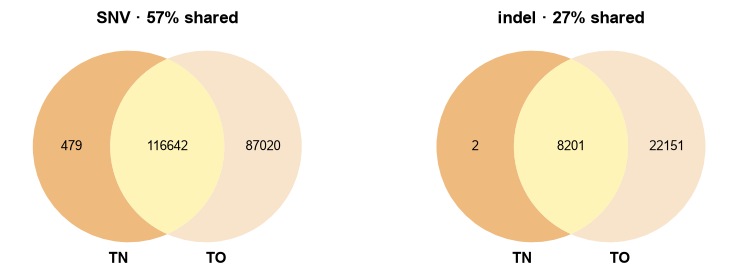

In [6]:
from matplotlib_venn import venn2, venn3
from matplotlib_venn.layout.venn2 import DefaultLayoutAlgorithm as _Venn2Layout
from matplotlib_venn.layout.venn3 import DefaultLayoutAlgorithm as _Venn3Layout

# Fixed subset sizes: every circle and overlap is drawn the same size whatever the counts, so the
# numbers are read from the labels rather than estimated from wildly unequal areas.
_VENN2_LAYOUT = _Venn2Layout(fixed_subset_sizes=(1, 1, 1))
_VENN3_LAYOUT = _Venn3Layout(fixed_subset_sizes=(1, 1, 1, 1, 1, 1, 1))

def draw_tnto_venns(fig, spec, stack=False):
    """SNV and indel TN-vs-TO Venn, pooled over BENCH_CELLS. stack=True puts them in one column."""
    sub = spec.subgridspec(2, 1, hspace=0.45) if stack else spec.subgridspec(1, 2, wspace=0.30)
    axes = []
    for j, kind in enumerate(("snv", "indel")):
        ax = fig.add_subplot(sub[j, 0] if stack else sub[0, j]); axes.append(ax)
        counts = BENCH[kind][0]
        tp, fn, fp = counts["TP"], counts["FN"], counts["FP"]
        union = tp + fn + fp
        # venn2 subset order = (A only, B only, AB) = (FN, FP, TP); A = TN (truth), B = TO (test)
        v = venn2(subsets=(fn, fp, tp), set_labels=(TRUTH, TEST),
                  set_colors=(ARMS[TRUTH]["color"], ARMS[TEST]["color"]), alpha=0.55,
                  ax=ax, layout_algorithm=_VENN2_LAYOUT)
        for t in (v.subset_labels or []):
            if t:
                t.set_fontsize(7.5)
        for t in (v.set_labels or []):
            if t:
                t.set_fontsize(9); t.set_fontweight("bold")
        pct = 100 * tp / union if union else 0
        ax.set_title(f"{KIND_LABEL[kind]} · {pct:.0f}% shared", fontsize=10, weight="bold",
                     pad=4)
    return axes

fig = plt.figure(figsize=(6.4, 3.4))
draw_tnto_venns(fig, fig.add_gridspec(1, 1, left=0.04, right=0.97, top=0.84, bottom=0.04)[0, 0])
plt.show()

## 7 · SNV mutational spectrum and allele frequency

One row per benchmark set (TP, FP, FN). Left: the SBS-96 trinucleotide profile as a fraction of
that set's SNVs, coloured by the six pyrimidine substitution classes. Right: the tumour VAF
distribution as a fraction of that set's SNVs per 0.04-wide bin — both arms for TP, TN only for
FN, TO only for FP. Both y-axes are shared across the three rows, so the rows are directly
comparable.

The FP set is the one to read closely: calls present in tumour-only but not in the matched
tumour/normal run are expected to carry a distinct VAF distribution, because a heterozygous
germline variant leaking through sits near 0.5 rather than at the tumour's somatic VAF.

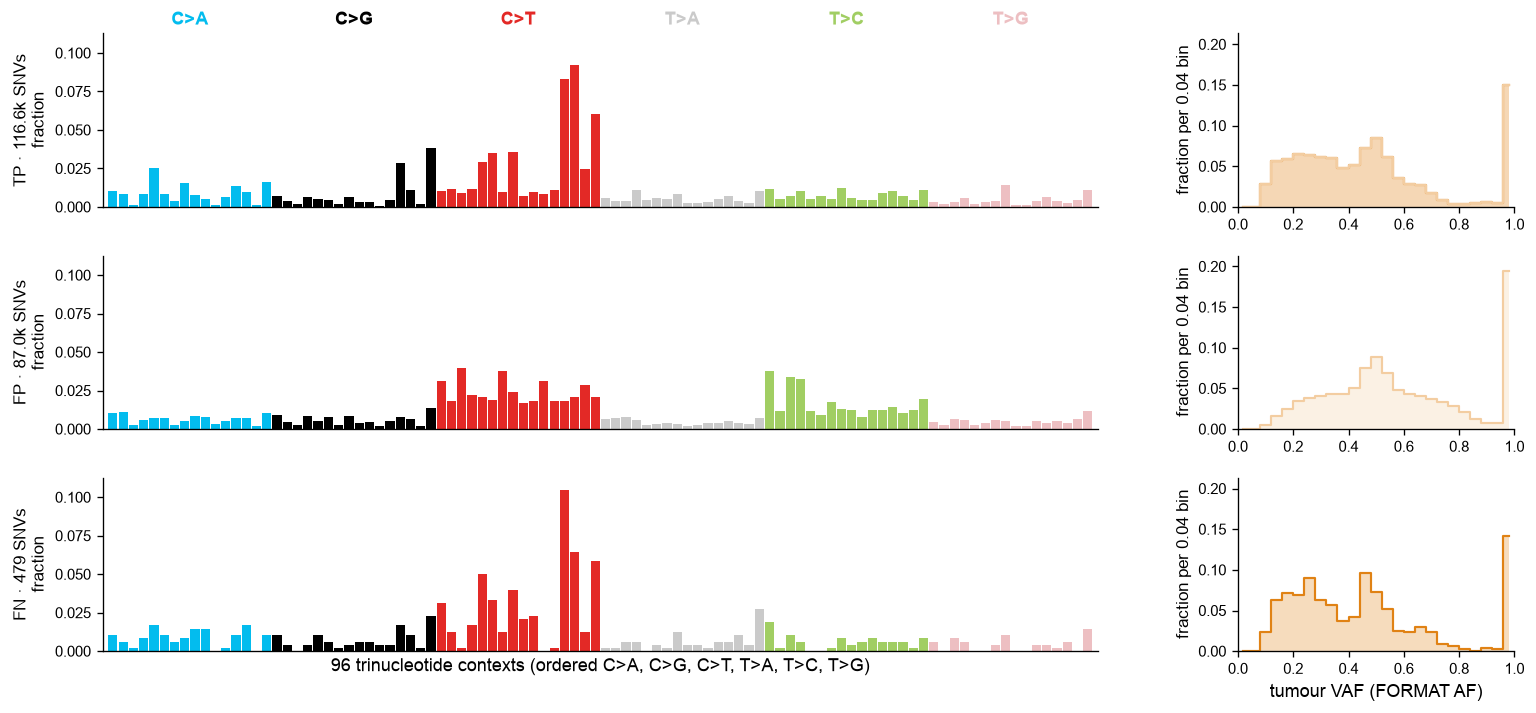

In [20]:
VAF_BINS = np.linspace(0, 1, 26)                 # 25 bins, width 0.04
_VAF_CTR = (VAF_BINS[:-1] + VAF_BINS[1:]) / 2
_SUB_PT = 3                       # SNV class labels above the top row, in points above its axes
_STRIP_PT, _STRIP_H = 9, 11       # ID-83 header strip: centre height above the axes, thickness (points)
_ID83_TICK_FS = 8.5               # ID-83 per-bar numbers; the x-axis labels below hang off this

# ID-83 sections: (section name, first channel, last + 1).
ID83_GROUPS = [("1bp deletion", 0, 12),
               ("1bp insertion", 12, 24),
               (">1bp deletion at repeats", 24, 48),
               (">1bp insertion at repeats", 48, 72),
               ("microhomology\ndeletion", 72, 83)]
ID83_BOUNDS = [12, 24, 48, 72]
# What the per-bar number counts. Adjacent sections that count the same thing share one bracket.
# The last bar of each block is open-ended; the bracket says so, the bar label alone has no room.
ID83_MEANINGS = [("homopolymer length (6 = 6+)", 0, 24),
                 ("repeat-unit count (5 = 5+)", 24, 72),
                 ("microhomology\nlength", 72, 83)]

def _vaf_frac(values):
    v = np.array([x for x in values if x is not None and not np.isnan(x)])
    if v.size == 0:
        return None, 0
    counts, _ = np.histogram(v, bins=VAF_BINS)
    return counts / v.size, int(v.size)

def _xdata_ypt(ax, dy):
    """x in data units, y at the axes' bottom (dy < 0) or top (dy > 0) edge plus dy points."""
    base = ax.get_xaxis_transform()
    return mtransforms.offset_copy(base, fig=ax.figure, y=dy, units="points")

def _above(ax, x, pt, text, **kw):
    ax.text(x, 1, text, transform=_xdata_ypt(ax, pt), ha="center", va="bottom", **kw)

def _snv_bands(ax):
    for ci, cls in enumerate(SBS_CLASSES):
        _above(ax, ci * 16 + 7.5, _SUB_PT, cls, fontsize=11, weight="bold",
               color=(SBS_COLORS[cls] if cls != "C>G" else "#000"))

def _id83_bands(ax):
    # COSMIC-style header: a coloured strip per sub-block (base C/T or indel size), section names
    # above it. What the per-bar number counts is written below the x-axis of the last row instead
    # (_id83_xmeanings).
    subs = [("C", 0, 6), ("T", 6, 12), ("C", 12, 18), ("T", 18, 24),
            ("2", 24, 30), ("3", 30, 36), ("4", 36, 42), ("5+", 42, 48),
            ("2", 48, 54), ("3", 54, 60), ("4", 60, 66), ("5+", 66, 72),
            ("2", 72, 73), ("3", 73, 75), ("4", 75, 78), ("5+", 78, 83)]
    strip = _xdata_ypt(ax, _STRIP_PT)
    for name, a, b in subs:
        col = id83_color(ID83_CHANNELS[a])
        ax.plot([a - 0.4, b - 0.6], [1, 1], transform=strip, color=col, lw=_STRIP_H,
                solid_capstyle="butt", clip_on=False)
        light = np.dot(mcolors.to_rgb(col), (0.299, 0.587, 0.114)) > 0.6
        ax.text((a + b - 1) / 2, 1, name, transform=strip, ha="center", va="center",
                fontsize=8, weight="bold", color=("#333" if light else "white"))
    for name, a, b in ID83_GROUPS:
        _above(ax, (a + b - 1) / 2, _STRIP_PT + _STRIP_H / 2 + 3, name, fontsize=9, weight="bold",
               color="#333", linespacing=1.0)

def _id83_xmeanings(ax, xlab):
    # Below the per-bar numbers: a bracket per meaning, its name, then the axis label.
    y0 = -(_ID83_TICK_FS + 6)
    for meaning, a, b in ID83_MEANINGS:
        ax.plot([a - 0.4, b - 0.6], [0, 0], transform=_xdata_ypt(ax, y0), color="#333", lw=1.0,
                clip_on=False, solid_capstyle="butt")
        ax.text((a + b - 1) / 2, 0, meaning, transform=_xdata_ypt(ax, y0 - 3), ha="center",
                va="top", fontsize=10, weight="bold", color="#333", linespacing=1.0)
    ax.text(len(ID83_CHANNELS) / 2 - 0.5, 0, xlab, transform=_xdata_ypt(ax, y0 - 28),
            ha="center", va="top", fontsize=11, weight="bold")

def _id83_xticklabels():
    labs = []
    for ch in ID83_CHANNELS:
        sz, typ, cat, i = ch.split(":"); i = int(i)
        if cat == "M":
            labs.append(str(i))                              # microhomology length (bp)
        elif sz == "1" and typ == "Del":
            labs.append(str(i + 1))                          # homopolymer length 1..6 (6 = 6+)
        else:
            labs.append(str(i))                              # repeat-unit count 0..5 (5 = 5+)
    return labs

def draw_profiles(fig, spec, kind):
    """Three rows (TP / FP / FN): mutational profile on the left, VAF distribution on the right."""
    channels = CHANNELS[kind]
    _counts, prof, vafs = BENCH[kind]
    if kind == "snv":
        colors = [SBS_COLORS[b.split("_")[0]] for b in channels]; bands = _snv_bands
        noun = "SNVs"
        xlab = "96 trinucleotide contexts (ordered C>A, C>G, C>T, T>A, T>C, T>G)"
    else:
        colors = [id83_color(ch) for ch in channels]; bands = _id83_bands
        noun = "indels"
        xlab = "COSMIC ID-83 indel channels"

    fracs = {r: (prof[r] / prof[r].sum() if prof[r].sum() else prof[r]) for r in BENCH_REGIONS}
    ymax = max((f.max() for f in fracs.values() if f.size and f.max() > 0), default=1.0)
    vaf_h = {r: {a: _vaf_frac(vafs[r][a]) for a in BENCH_ARMS[r]} for r in BENCH_REGIONS}
    vmax = max((float(f.max()) for r in BENCH_REGIONS for f, _ in vaf_h[r].values()
                if f is not None), default=1.0)

    # The ID-83 profile is the wider one, so it needs a smaller relative gap for the same spacing.
    sub = spec.subgridspec(len(BENCH_REGIONS), 2, width_ratios=[3.6, 1.0], hspace=0.28,
                           wspace=0.22 if kind == "snv" else 0.13)
    axes = []
    for r, region in enumerate(BENCH_REGIONS):
        axp = fig.add_subplot(sub[r, 0]); axes.append(axp)
        tot = prof[region].sum()
        axp.bar(range(len(channels)), fracs[region], width=0.9, color=colors, linewidth=0)
        axp.set_xlim(-1, len(channels)); axp.set_xticks([]); axp.set_ylim(0, ymax * 1.08)
        if kind == "indel":
            for bnd in ID83_BOUNDS:
                axp.axvline(bnd - 0.5, color="#BBBBBB", lw=0.7, zorder=1)
        # No title: the set and its size go in the y-label instead.
        axp.set_ylabel(f"{region} · {fmt(tot)} {noun}\nfraction", fontsize=10)
        axp.tick_params(axis="y", labelsize=9)
        if tot == 0:
            axp.text(0.5, 0.5, f"no {noun}", transform=axp.transAxes, ha="center", va="center",
                     fontsize=11, color="#999")
        if r == 0:
            bands(axp)

        axv = fig.add_subplot(sub[r, 1]); axes.append(axv)
        for a in BENCH_ARMS[region]:
            frac, n = vaf_h[region][a]
            if frac is None:
                continue
            col = ARMS[a]["color"]
            axv.fill_between(_VAF_CTR, frac, step="mid", color=col, alpha=0.28, lw=0)
            axv.step(_VAF_CTR, frac, where="mid", color=col, lw=1.3)
        axv.set_xlim(0, 1); axv.set_ylim(0, vmax * 1.1)
        axv.set_ylabel("fraction per 0.04 bin", fontsize=10); axv.tick_params(axis="both", labelsize=9)
        if r == len(BENCH_REGIONS) - 1:
            if kind == "indel":
                axp.set_xticks(range(len(channels)))
                axp.set_xticklabels(_id83_xticklabels(), fontsize=_ID83_TICK_FS)
                axp.tick_params(axis="x", length=1.5, pad=1)
                _id83_xmeanings(axp, xlab)
            else:
                axp.set_xlabel(xlab, fontsize=11)
            axv.set_xlabel("tumour VAF (FORMAT AF)", fontsize=11)
    return axes

fig = plt.figure(figsize=(13.0, 6.6))
draw_profiles(fig, fig.add_gridspec(1, 1, left=0.065, right=0.97, top=0.88, bottom=0.10)[0, 0], "snv")
plt.show()

## 8 · indel mutational spectrum and allele frequency

The same layout for indels: COSMIC **ID-83** profile on the left, VAF distribution on the right,
rows TP / FP / FN. Channels come from `REF`/`ALT` plus the SAGE `REP_C` / `REP_S` / `RC_MH`
annotations; the labels under the last row give what each bar's number counts — homopolymer
length, repeat-unit count or microhomology length, per section.

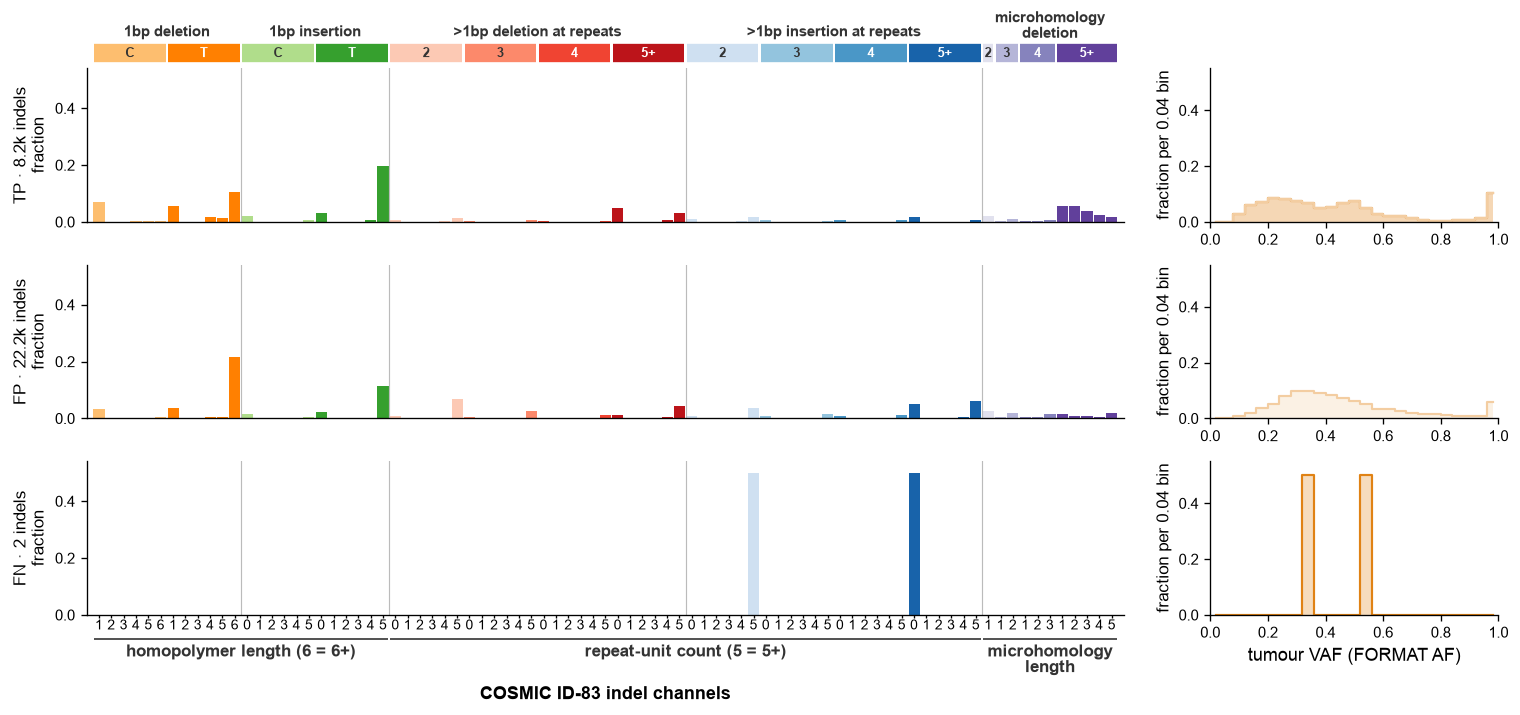

In [21]:
fig = plt.figure(figsize=(13.0, 6.6))
draw_profiles(fig, fig.add_gridspec(1, 1, left=0.065, right=0.97, top=0.86, bottom=0.17)[0, 0], "indel")
plt.show()

## 9 · Variant burden (TN vs TO, three platforms)

Absolute per-sample counts of SNVs, MNVs, indels, structural variants and copy-number-altered
segments, with the three platforms side by side per cell line and, within each platform, the
tumour/normal bar next to its tumour-only tint. Small variants are restricted to tumour
`AF ≥ VAF_MIN`; SV and CNA counts are not VAF-filtered.

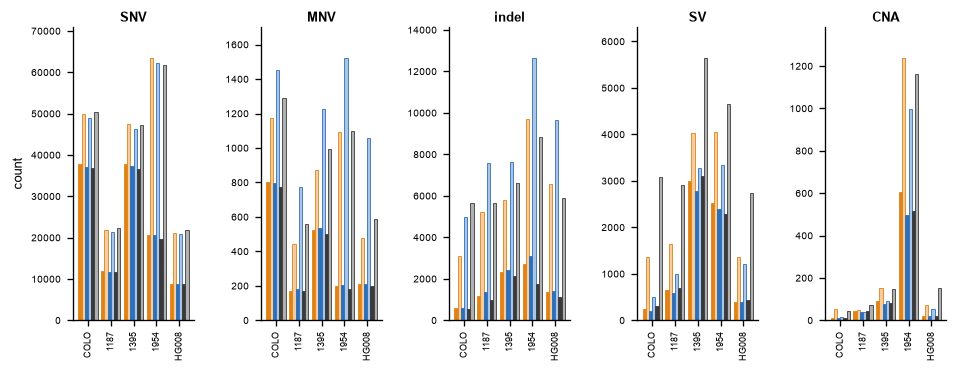

In [9]:
def _cmp_offsets(nP, nC):
    # nP*nC sub-bars per cell line, platform-major / run-type-minor, centred on the cell-line tick.
    w = 0.84 / (nP * nC)
    off = {(pi, ci): (pi * nC + ci - (nP * nC - 1) / 2) * w
           for pi in range(nP) for ci in range(nC)}
    return off, w

def draw_burden(fig, spec):
    plats = list(PLATFORMS); conds = list(CONDITIONS)
    off, w = _cmp_offsets(len(plats), len(conds))
    sub = spec.subgridspec(1, len(VAR_TYPES), wspace=0.55)
    axes = []
    for k, vt in enumerate(VAR_TYPES):
        ax = fig.add_subplot(sub[0, k]); axes.append(ax)
        x = np.arange(len(CELLS))
        for pi, p in enumerate(plats):
            base = PLATFORMS[p]["color"]
            for ci, cond in enumerate(conds):
                vals = [DATA[p][cond][c]["counts"].get(vt, np.nan) if c in DATA[p][cond]
                        else np.nan for c in CELLS]
                ax.bar(x + off[(pi, ci)], vals, w, color=cond_face(base, cond),
                       edgecolor=base, linewidth=0.5, zorder=2)
        ax.set_title(vt, fontsize=7.5, pad=3)
        ax.set_xticks(x); ax.set_xticklabels([short_cell(c) for c in CELLS], rotation=90,
                                             fontsize=5.5)
        ax.tick_params(axis="y", labelsize=6); ax.margins(y=0.12)
    axes[0].set_ylabel("count")
    return axes

fig = plt.figure(figsize=(8.0, 3.6))
draw_burden(fig, fig.add_gridspec(1, 1, left=0.08, right=0.99, top=0.90, bottom=0.22)[0, 0])
plt.show()

## 10 · SV class composition (TN vs TO, three platforms)

The same grid as the burden panel, each bar a stacked SV-class fraction. The coloured `I` / `R` /
`U` tick sits under each platform's TN + TO pair, the cell line under the group. Structural
variants have no per-allele VAF, so this panel is over all PASS SVs.

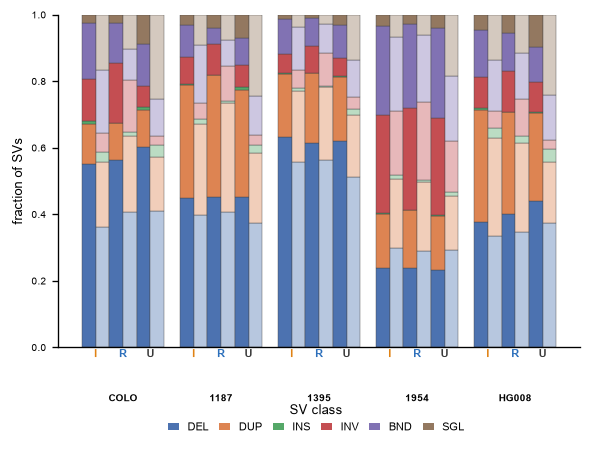

In [10]:
def draw_sv_composition(fig, spec):
    ax = fig.add_subplot(spec)
    plats = list(PLATFORMS); conds = list(CONDITIONS)
    off, w = _cmp_offsets(len(plats), len(conds))
    tickpos, ticklab, tickcol = [], [], []
    for xi, c in enumerate(CELLS):
        for pi, p in enumerate(plats):
            # platform initial centred under that platform's TN + TO pair
            tickpos.append(xi + (off[(pi, 0)] + off[(pi, len(conds) - 1)]) / 2)
            ticklab.append(PLATFORMS[p]["init"]); tickcol.append(PLATFORMS[p]["color"])
            for ci, cond in enumerate(conds):
                if c not in DATA[p][cond]:
                    continue
                sv = DATA[p][cond][c]["sv"]; n = sum(sv.values()) or 1
                bottom = 0.0
                for cls in SV_ORDER:
                    frac = sv.get(cls, 0) / n
                    ax.bar(xi + off[(pi, ci)], frac, bottom=bottom, width=w,
                           color=cond_face(SV_COLORS[cls], cond),
                           edgecolor="#444444", linewidth=0.25)
                    bottom += frac
    ax.set_ylim(0, 1); ax.set_ylabel("fraction of SVs"); ax.tick_params(axis="y", labelsize=6)
    ax.set_xticks(tickpos); ax.set_xticklabels(ticklab, fontsize=6.5, fontweight="bold")
    for t, col in zip(ax.get_xticklabels(), tickcol):
        t.set_color(col)
    ax.tick_params(axis="x", length=0, pad=1)
    for xi, c in enumerate(CELLS):            # cell-line label below the platform initials
        ax.text(xi, -0.14, short_cell(c), transform=ax.get_xaxis_transform(),
                ha="center", va="top", fontsize=6, weight="bold")
    return [ax]

fig = plt.figure(figsize=(5.0, 3.6))
draw_sv_composition(fig, fig.add_gridspec(1, 1, left=0.12, right=0.99, top=0.95, bottom=0.18)[0, 0])
fig.legend(handles=[Patch(facecolor=SV_COLORS[c], label=c) for c in SV_ORDER],
           loc="lower center", bbox_to_anchor=(0.55, -0.04), ncol=6, fontsize=6.5,
           title="SV class", handlelength=1.0, columnspacing=1.0)
plt.show()

## 11 · Cross-platform concordance (TN and TO)

Three-way SNV and indel Venns over the cell lines sequenced on all three platforms, summed over
the seven regions and drawn once per run type. Membership is PASS presence, so a variant called
on two platforms counts as shared even when its VAF differs; the VAF ≥ 10% rule is the inclusion
gate on the variant, not on the membership. The title gives the fraction of the union that all
three platforms call.

Reading the two rows against each other is the point: if tumour-only degraded calling in a
platform-specific way, the TO row's core would shrink relative to the TN row's.

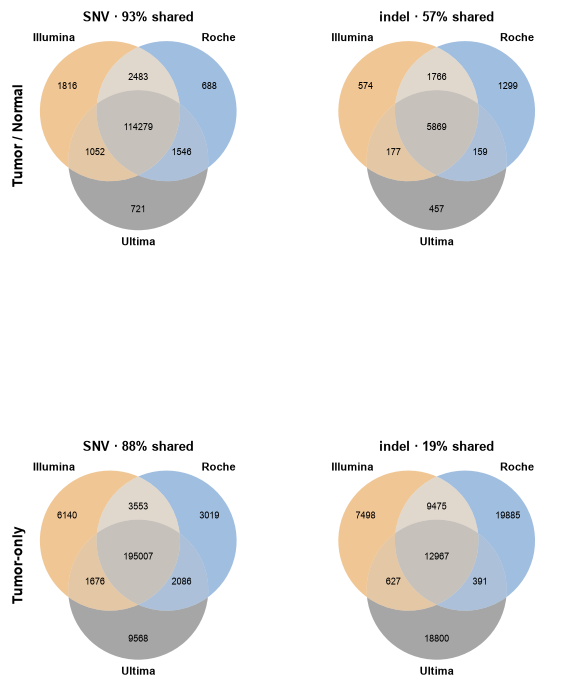

In [11]:
def draw_platform_venns(fig, spec, conds=None):
    """One Venn row per run type, columns SNV | indel; all three platforms in each Venn."""
    conds = list(CONDITIONS) if conds is None else conds
    plats = list(PLATFORMS)
    sub = spec.subgridspec(len(conds), 2, hspace=0.55, wspace=0.30)
    axes = {}
    for ri, cond in enumerate(conds):
        shared = [c for c in CELLS if all(c in DATA[p][cond] for p in plats)]
        row = []
        for j, kind in enumerate(("snv", "indel")):
            ax = fig.add_subplot(sub[ri, j]); row.append(ax)
            reg = np.zeros(7)   # A only, B only, AB, C only, AC, BC, ABC
            for cl in shared:
                sets = [DATA[p][cond][cl]["keys"][kind] for p in plats]
                universe = set().union(*[DATA[p][cond][cl]["hi_keys"][kind] for p in plats])
                for k in universe:
                    a, b, c = (k in sets[0]), (k in sets[1]), (k in sets[2])
                    if   a and not b and not c: reg[0] += 1
                    elif b and not a and not c: reg[1] += 1
                    elif a and b and not c:     reg[2] += 1
                    elif c and not a and not b: reg[3] += 1
                    elif a and c and not b:     reg[4] += 1
                    elif b and c and not a:     reg[5] += 1
                    else:                       reg[6] += 1
            union = reg.sum(); pct = 100 * reg[6] / union if union else 0
            v = venn3(subsets=tuple(int(x) for x in reg), set_labels=plats,
                      set_colors=[PLATFORMS[p]["color"] for p in plats], alpha=0.45, ax=ax,
                      layout_algorithm=_VENN3_LAYOUT)
            for t in (v.set_labels or []):
                if t:
                    t.set_fontsize(6.5); t.set_fontweight("bold")
            for t in (v.subset_labels or []):
                if t:
                    t.set_fontsize(5.4)
            ax.set_title(f"{KIND_LABEL[kind]} · {pct:.0f}% shared", fontsize=7.5, pad=2)
        axes[cond] = row
    return axes

def label_venn_rows(fig, venn_axes):
    # Run-type label down the left edge of each Venn row (placed after the canvas is laid out).
    for cond, row in venn_axes.items():
        pos = [a.get_position() for a in row]
        fig.text(min(p.x0 for p in pos) - 0.008,
                 (min(p.y0 for p in pos) + max(p.y1 for p in pos)) / 2,
                 CONDITIONS[cond]["label"], rotation=90, va="center", ha="center",
                 fontsize=8.5, weight="bold")

fig = plt.figure(figsize=(5.0, 6.4))
_va = draw_platform_venns(fig, fig.add_gridspec(1, 1, left=0.10, right=0.98,
                                                top=0.95, bottom=0.03)[0, 0])
fig.canvas.draw(); label_venn_rows(fig, _va)
plt.show()

## 12 · Composite figure

Two frames on one canvas. Top: the Illumina TN-vs-TO benchmark — concordance Venns, then the SNV
and indel mutational profiles with their VAF distributions. Bottom: the cross-platform view —
variant burden, SV class composition and the three-way concordance Venns for each run type.

Panel letters are deliberately absent; they are added when the figure is assembled for the
manuscript.

Wrote: figures/extended_figure_6.pdf figures/extended_figure_6.svg figures/extended_figure_6.png


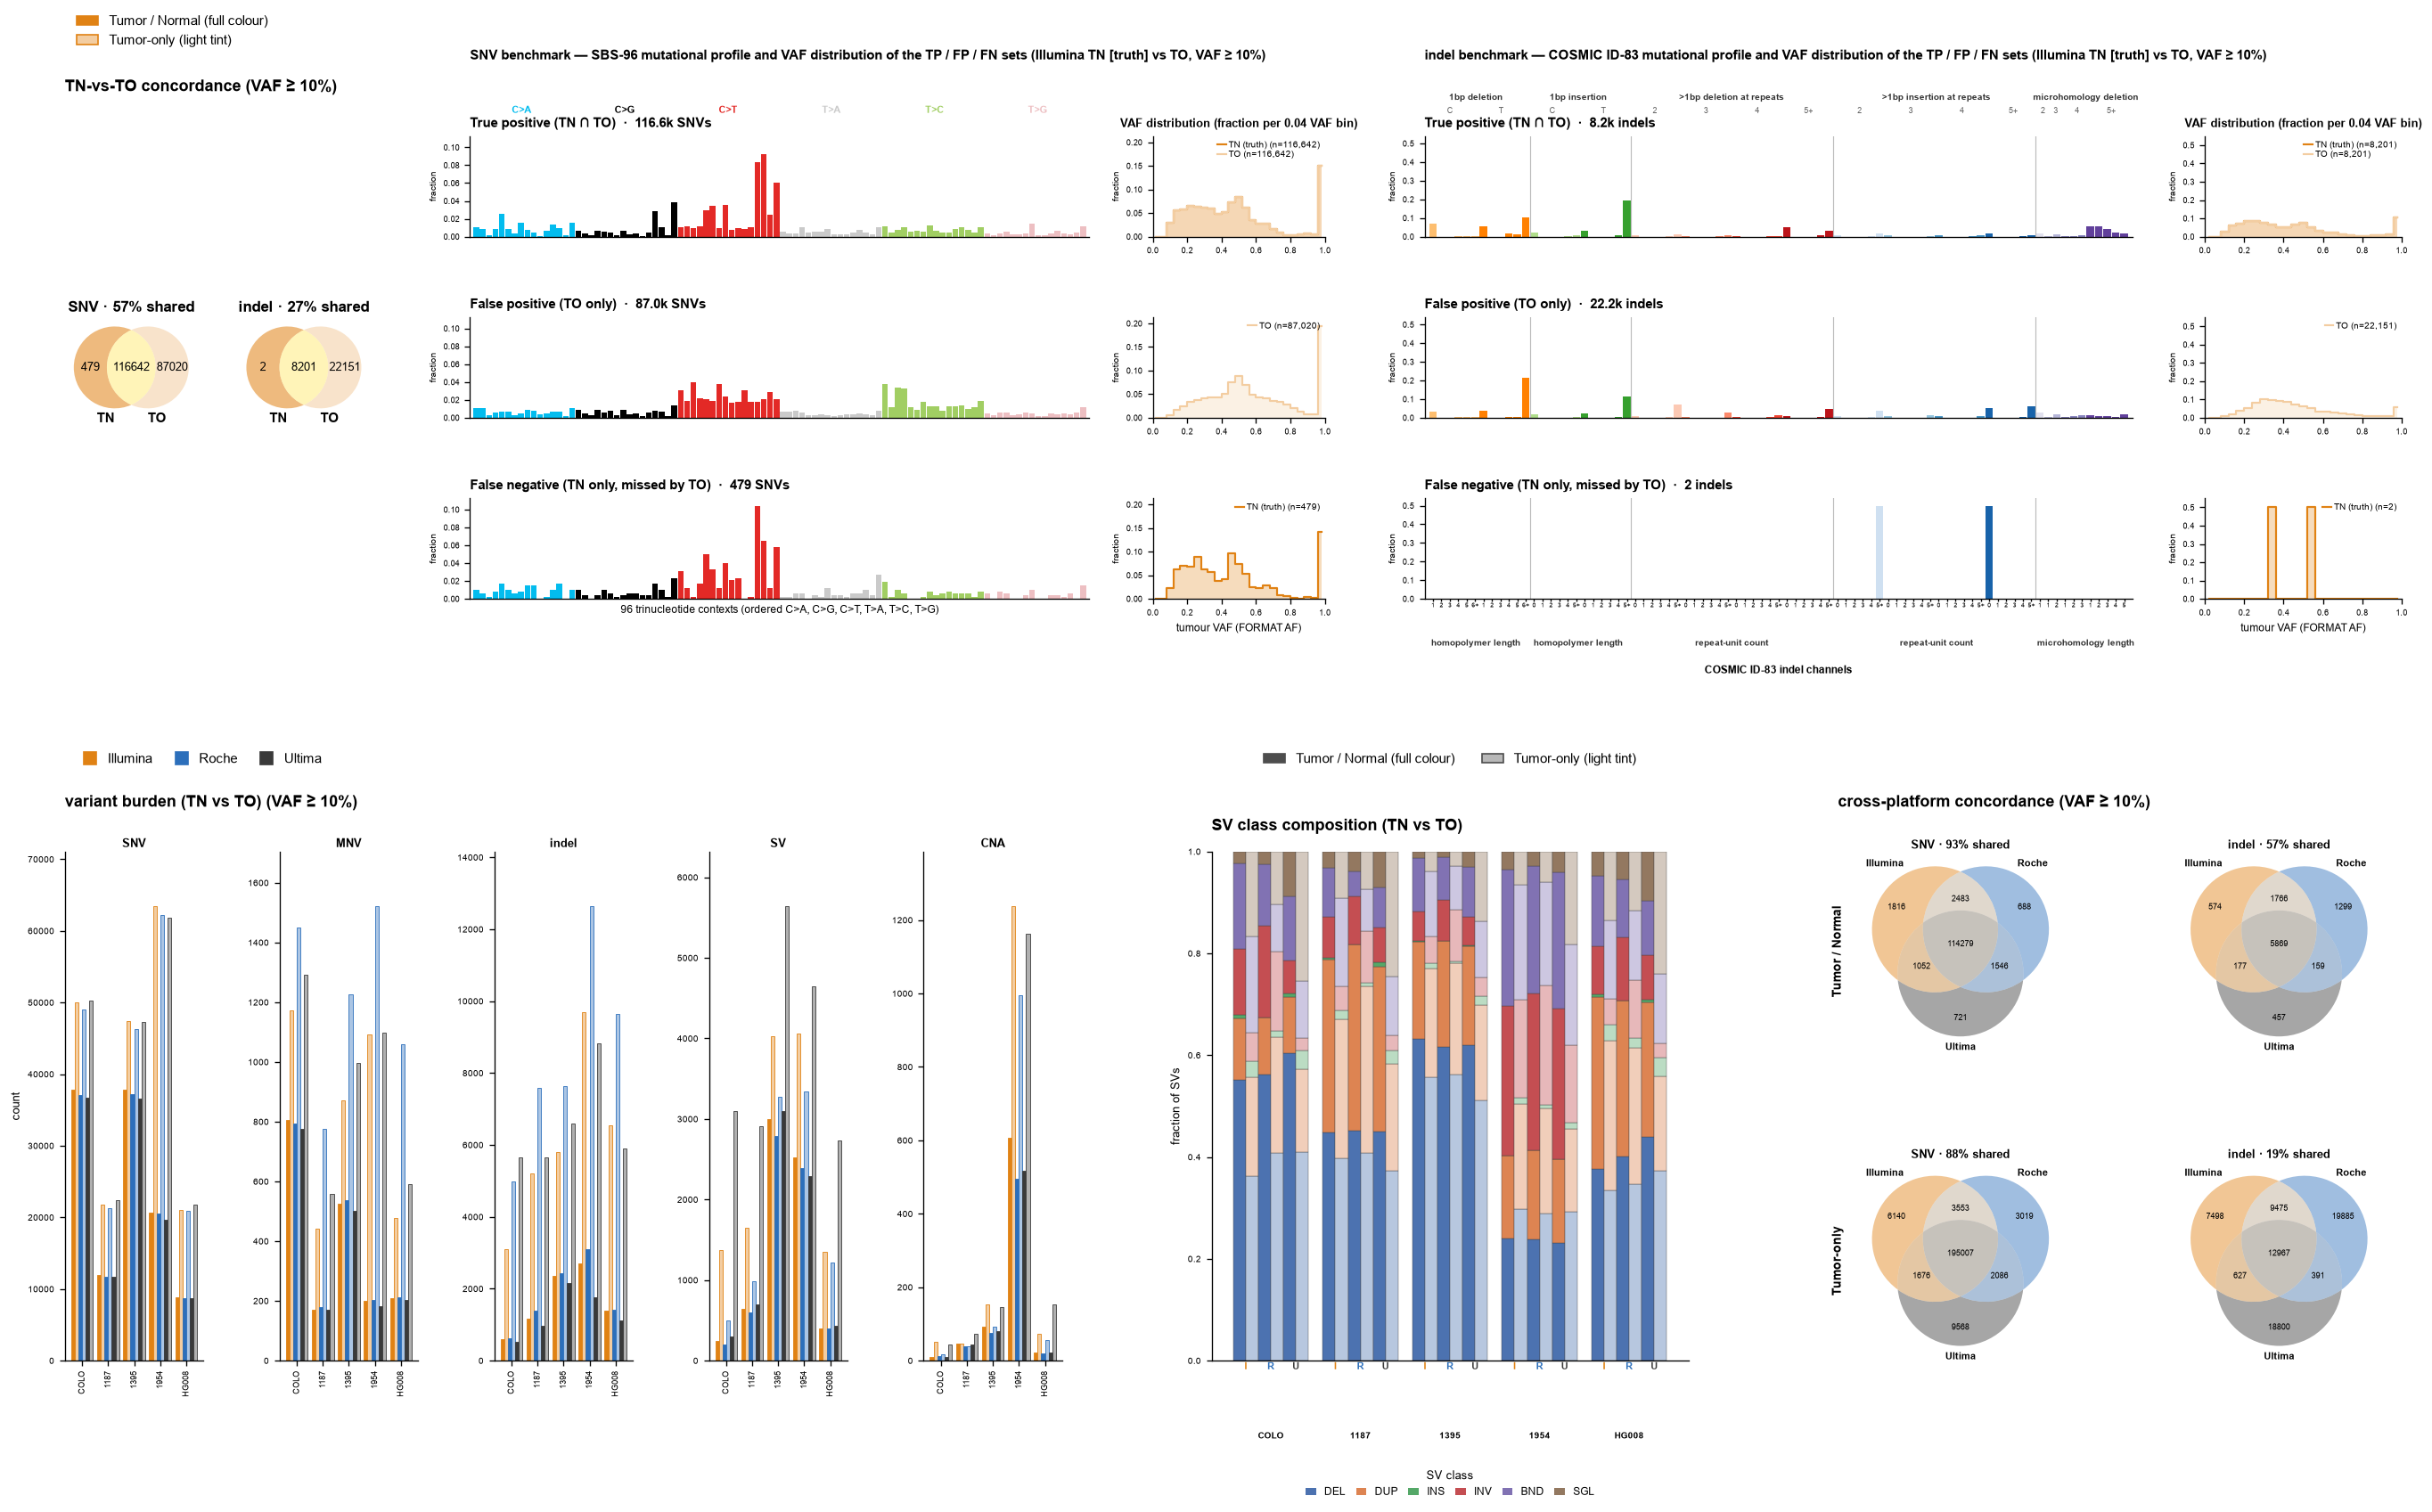

In [12]:
def composite_figure():
    fig = plt.figure(figsize=(23.0, 12.6))
    # The indel profile hangs its channel labels a long way below its last row, so the two
    # frames need a gutter: the bottom frame's legend row lives in it.
    outer = fig.add_gridspec(2, 1, height_ratios=[1.0, 1.10], hspace=0.40,
                             left=0.035, right=0.985, top=0.905, bottom=0.075)
    # ---- top frame: Illumina TN-vs-TO benchmark ------------------------------------------------
    top = outer[0, 0].subgridspec(1, 3, width_ratios=[0.75, 3.4, 4.9], wspace=0.13)
    axVenn = draw_tnto_venns(fig, top[0, 0], stack=True)
    axSNV  = draw_profiles(fig, top[0, 1], "snv")
    axIND  = draw_profiles(fig, top[0, 2], "indel")
    # ---- bottom frame: three platforms, TN vs TO -----------------------------------------------
    bot = outer[1, 0].subgridspec(1, 3, width_ratios=[4.6, 2.2, 2.6], wspace=0.22)
    axBurden = draw_burden(fig, bot[0, 0])
    axSV     = draw_sv_composition(fig, bot[0, 1])
    axPlat   = draw_platform_venns(fig, bot[0, 2])

    fig.canvas.draw()
    label_venn_rows(fig, axPlat)

    # Panel captions, at each group's left edge and above its top row. No panel letters — they are
    # added when the figure is assembled for the manuscript. The Venn axes are aspect-corrected at
    # draw time, so captions anchor on the ORIGINAL gridspec box, not the shrunk one.
    BENCH_CAP = ("{kind} benchmark — {prof} mutational profile and VAF distribution of the "
                 "TP / FP / FN sets ({plat} {truth} [truth] vs {test}, VAF \u2265 {pct:.0f}%)")
    _bench = dict(plat=BENCH_PLATFORM, truth=TRUTH, test=TEST, pct=VAF_MIN * 100)
    for group, text, dy, size in (
            (axVenn,   f"TN-vs-TO concordance{VAF_TAG}",                            0.028, 10.5),
            (axSNV,    BENCH_CAP.format(kind="SNV", prof="SBS-96", **_bench),       0.050,  9.0),
            (axIND,    BENCH_CAP.format(kind="indel", prof="COSMIC ID-83", **_bench), 0.050, 9.0),
            (axBurden, f"variant burden ({TRUTH} vs {TEST}){VAF_TAG}",              0.028, 10.5),
            (axSV,     f"SV class composition ({TRUTH} vs {TEST})",                 0.012, 10.5),
            (axPlat[TRUTH], f"cross-platform concordance{VAF_TAG}",                 0.028, 10.5)):
        p = group[0].get_position(original=True)
        fig.text(p.x0, p.y1 + dy, text, fontsize=size, weight="bold", ha="left", va="bottom")

    # ---- legends -------------------------------------------------------------------------------
    def _cond_patches(base):
        return [Patch(facecolor=cond_face(base, c), edgecolor=base,
                      label=CONDITIONS[c]["label"]
                            + (" (full colour)" if c == TRUTH else " (light tint)"))
                for c in CONDITIONS]

    # top frame: run type in the benchmark platform's hue
    fig.legend(handles=_cond_patches(BENCH_COLOR), loc="upper left",
               bbox_to_anchor=(0.035, 0.995), ncol=1, fontsize=9, handlelength=1.6)
    # bottom frame: platforms on the left and the same run-type key in neutral grey, both anchored
    # from below so they grow away from the panel captions underneath them
    _burden = axBurden[0].get_position(original=True)
    _sv = axSV[0].get_position(original=True)
    _y = _burden.y1 + 0.050
    fig.legend(handles=[Line2D([0], [0], marker="s", ls="", ms=8,
                               color=PLATFORMS[p]["color"], label=p) for p in PLATFORMS],
               loc="lower left", bbox_to_anchor=(0.035, _y), ncol=3, fontsize=9,
               handletextpad=0.3, columnspacing=1.2)
    fig.legend(handles=_cond_patches("#4D4D4D"), loc="lower center",
               bbox_to_anchor=((_sv.x0 + _sv.x1) / 2, _y), ncol=2, fontsize=9, handlelength=1.6)
    fig.legend(handles=[Patch(facecolor=SV_COLORS[c], label=c) for c in SV_ORDER],
               loc="upper center", bbox_to_anchor=((_sv.x0 + _sv.x1) / 2, _sv.y0 - 0.068),
               ncol=6, fontsize=7, title="SV class", handlelength=1.0, columnspacing=1.0)
    return fig

fig = composite_figure()
stem = EXPORT_DIR / "extended_figure_6"
for ext in ("pdf", "svg", "png"):
    fig.savefig(f"{stem}.{ext}", bbox_inches="tight")
print("Wrote:", *(f"{stem}.{e}" for e in ("pdf", "svg", "png")))
plt.show()